# 06 · Network Upgrade Optimization
*EV capacity planning for PowerCharge Utilities · notebook 6 of 8 · Anna Tafri*

Reads: `data/processed/ev_events_clean.csv`, `substations_clean.csv`, `bottleneck_scores.csv`  
Writes: `reports/upgrade_plan.csv`, `reports/budget_frontier.csv`, `reports/figures/06_*.png`

### Business question
> What is the lowest-cost mix of interventions that keeps every substation within its planning limit at 20× EV growth? And if the budget is capped, what should be funded first?

The traditional answer is to reinforce every substation that breaches, with a bigger transformer and new feeders. It is reliable, but it is expensive and lumpy. Utilities now also use non-wire alternatives such as smart charging, time-of-use tariffs, and battery buffers. These can be cheaper where the problem is *when* and *how fast* vehicles charge, which Notebook 05 found is often the case here.

This notebook formulates the choice as a Mixed-Integer Linear Program (MILP) and solves it with `scipy.optimize.milp`, which is included with Anaconda, so no extra installs are needed.


## 0. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy.optimize import milp, LinearConstraint, Bounds

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED = PROJECT_ROOT / "data" / "processed"
REPORTS = PROJECT_ROOT / "reports"
FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from ev_utils import capacity_model

pd.set_option("display.float_format", "{:,.2f}".format)

INK, INK_2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#8a8984", "#e4e3df", "#fcfcfb"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # fixed categorical order
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_2, "axes.edgecolor": GRID, "text.color": INK,
    "xtick.color": INK_2, "ytick.color": INK_2,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "legend.frameon": False,
})
def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")

events = pd.read_csv(PROCESSED / "ev_events_clean.csv", parse_dates=["timestamp"])
subs = pd.read_csv(PROCESSED / "substations_clean.csv")
scores = pd.read_csv(PROCESSED / "bottleneck_scores.csv", index_col="substation_id")

CHARGER_KW = {"Type 1": 7.4, "Type 2": 22.0, "DC Fast": 50.0}
PLANNING_LIMIT, COINCIDENCE, DESIGN_GROWTH = 0.80, 0.7, 20

## 1. The problem to solve: capacity deficits at 20× growth
For each substation, the deficit is how many MW of peak load must be removed (or how much capacity must be added) to bring it back to the 80% planning limit.

We solve two cases:
- **Base case:** 65% existing base load, the central assumption from Notebook 04.
- **Robust case:** 70% base load. Notebook 04 showed base load is the biggest unknown, so a prudent plan should also hold if it is higher.

In [2]:
def deficits(base_load_util):
    c = capacity_model(events, subs, CHARGER_KW, base_load_util, COINCIDENCE, PLANNING_LIMIT, growth=DESIGN_GROWTH)
    c["ev_peak_20x"] = c["ev_peak_mw"] * DESIGN_GROWTH
    c["deficit_mw"] = (c["peak_load_mw"] - PLANNING_LIMIT * c["capacity_mw"]).clip(lower=0)
    c = c[c["deficit_mw"] > 0.01].join(scores[["fast_charger_share", "risk_score", "tier"]])
    return c.sort_values("deficit_mw", ascending=False)

CASES = {"Base case (65% base load)": deficits(0.65), "Robust case (70% base load)": deficits(0.70)}
for name, d in CASES.items():
    print(f"{name}: {len(d)} substations, total deficit {d['deficit_mw'].sum():.1f} MW")
CASES["Base case (65% base load)"][["capacity_mw", "ev_peak_20x", "deficit_mw", "fast_charger_share", "tier"]]

Base case (65% base load): 9 substations, total deficit 20.2 MW
Robust case (70% base load): 17 substations, total deficit 47.8 MW


,capacity_mw,ev_peak_20x,deficit_mw,fast_charger_share,tier
substation_id,,,,,
Substation_560,65,17.72,7.97,0.95,Tier 1 - Act
Substation_258,22,7.00,3.70,1.00,Tier 1 - Act
Substation_301,20,5.24,2.24,0.00,Tier 1 - Act
Substation_64,26,5.60,1.70,1.00,Tier 1 - Act
Substation_516,88,14.70,1.50,1.00,Tier 1 - Act
Substation_720,21,4.20,1.05,1.00,Tier 1 - Act
Substation_999,43,7.45,1.00,0.75,Tier 1 - Act
Substation_470,52,8.76,0.96,0.72,Tier 1 - Act
Substation_11_B,43,6.52,0.07,0.86,Tier 1 - Act


## 2. The intervention menu
All costs are indicative planning figures (present value of capex plus about 10 years of operating cost). They sit in one table so a utility can replace them with its own unit costs.

| Option | Type | Relief (MW) | Indicative cost | Notes |
|---|---|---|---|---|
| Transformer uprate | Wire | +5 MW capacity to 4.0 MW usable at 80% | $0.9M per uprate (max 3) | Lumpy but permanent |
| New transformer bay | Wire | +20 MW capacity to 16 MW usable | $3.0M (max 1) | Large step; long lead time |
| Smart charging programme | Non-wire | 25% of the substation's EV peak | $0.10M + $0.04M per MW of EV peak | Software plus customer incentives |
| Time-of-use tariff | Non-wire | 10% of EV peak | $0.05M | Shifts charging out of 17:00–21:00 |
| Battery buffer | Non-wire | 0.5 MW per block | $0.35M per block | Only at DC fast sites, up to 50% of their load |

Non-wire relief is less certain than copper. Section 6 tests what happens if it delivers only half of what is planned.

In [3]:
OPTIONS = ["Transformer uprate", "New transformer bay", "Smart charging", "Time-of-use tariff", "Battery buffer"]
COST = {"uprate": 0.90, "bay": 3.00, "smart_fixed": 0.10, "smart_per_mw": 0.04, "tou": 0.05, "battery_block": 0.35}
RELIEF = {"uprate": 0.8 * 5, "bay": 0.8 * 20, "smart_share": 0.25, "tou_share": 0.10, "battery_block": 0.5}

# Cost per MW of relief at a typical at-risk substation (EV peak at 20x = 7 MW)
typical_ev = 7.0
menu = pd.DataFrame({
    "relief_mw": [RELIEF["uprate"], RELIEF["bay"], RELIEF["smart_share"] * typical_ev,
                  RELIEF["tou_share"] * typical_ev, RELIEF["battery_block"]],
    "cost_musd": [COST["uprate"], COST["bay"], COST["smart_fixed"] + COST["smart_per_mw"] * typical_ev,
                  COST["tou"], COST["battery_block"]],
}, index=OPTIONS)
menu["cost_per_mw_kusd"] = menu["cost_musd"] / menu["relief_mw"] * 1000
menu

,relief_mw,cost_musd,cost_per_mw_kusd
Transformer uprate,4.00,0.90,225.00
New transformer bay,16.00,3.00,187.50
Smart charging,1.75,0.38,217.14
Time-of-use tariff,0.70,0.05,71.43
Battery buffer,0.50,0.35,700.00


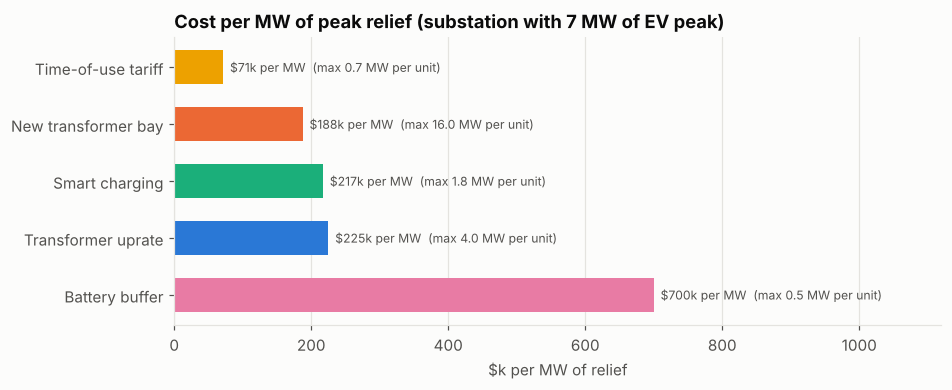

In [4]:
m = menu.sort_values("cost_per_mw_kusd")
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.barh(m.index[::-1], m["cost_per_mw_kusd"][::-1], color=[SERIES[OPTIONS.index(o)] for o in m.index[::-1]], height=0.6)
for yi, (v, r) in enumerate(zip(m["cost_per_mw_kusd"][::-1], m["relief_mw"][::-1])):
    ax.text(v + 10, yi, f"${v:,.0f}k per MW  (max {r:.1f} MW per unit)", va="center", fontsize=8, color=INK_2)
ax.set(title="Cost per MW of peak relief (substation with 7 MW of EV peak)", xlabel="$k per MW of relief",
       xlim=(0, m["cost_per_mw_kusd"].max() * 1.6))
ax.grid(axis="y", visible=False)
save(fig, "06_01_option_costs"); plt.show()

**Reading it:** tariffs and smart charging are the cheapest MW but their relief is capped, because they can only shift a share of the EV load. Uprates and new bays cost more per unit but deliver large, guaranteed blocks. Batteries are the most expensive per MW, but they come in small steps. No single option wins everywhere, which is exactly why this needs an optimiser rather than a rule of thumb.

## 3. The optimisation model
For every at-risk substation *s*, the decision variables are:

| Variable | Type | Meaning |
|---|---|---|
| $u_s$ | integer 0–3 | number of transformer uprates |
| $n_s$ | binary | build a new transformer bay |
| $m_s$ | binary | run a smart-charging programme |
| $t_s$ | binary | introduce a time-of-use tariff |
| $b_s$ | integer 0–B | number of 0.5 MW battery blocks (B depends on the DC fast-charger load) |
| $z_s$ | binary | substation is brought within its limit (used in the budget model) |

**Relief constraint (per substation):**
$4.0\,u_s + 16\,n_s + 0.25\,E_s\,m_s + 0.10\,E_s\,t_s + 0.5\,b_s \;\ge\; D_s\,z_s$
where $E_s$ is the EV peak at 20× and $D_s$ is the deficit.

**Model A, minimum cost:** fix every $z_s = 1$ and minimise total cost.
**Model B, fixed budget:** total cost ≤ budget; maximise $\sum_s w_s z_s$, where $w_s$ is the Notebook 05 risk score. In other words, *fix the riskiest substations the budget allows*.

In [5]:
def solve(d, budget=None, derate=1.0, wires_only=False):
    """Solve Model A (budget=None) or Model B (fixed budget). Returns one row per substation."""
    n_s, k = len(d), 6                                  # 6 variables per substation: u, n, m, t, b, z
    E, D = d["ev_peak_20x"].values, d["deficit_mw"].values
    b_max = np.floor(d["fast_charger_share"].fillna(0).values * E * 0.5 / RELIEF["battery_block"])

    cost = np.zeros(n_s * k)
    A_relief = np.zeros((n_s, n_s * k))
    lb, ub = np.zeros(n_s * k), np.zeros(n_s * k)
    for i in range(n_s):
        o = i * k
        cost[o:o + 5] = [COST["uprate"], COST["bay"], COST["smart_fixed"] + COST["smart_per_mw"] * E[i],
                         COST["tou"], COST["battery_block"]]
        A_relief[i, o:o + 6] = [RELIEF["uprate"], RELIEF["bay"], derate * RELIEF["smart_share"] * E[i],
                                derate * RELIEF["tou_share"] * E[i], derate * RELIEF["battery_block"], -D[i]]
        ub[o:o + 5] = [3, 1, 0 if wires_only else 1, 0 if wires_only else 1, 0 if wires_only else b_max[i]]
        lb[o + 5], ub[o + 5] = (1, 1) if budget is None else (0, 1)

    constraints = [LinearConstraint(A_relief, lb=0, ub=np.inf)]
    if budget is None:
        objective = cost
    else:
        constraints.append(LinearConstraint(cost[None, :], lb=0, ub=budget))
        objective = -np.repeat(d["risk_score"].values, k) * np.tile([0, 0, 0, 0, 0, 1], n_s) + 1e-4 * cost

    res = milp(objective, constraints=constraints, integrality=np.ones(n_s * k),
               bounds=Bounds(lb, ub), options={"time_limit": 60})
    if not res.success:
        raise RuntimeError(res.message)

    x = np.round(res.x).reshape(n_s, k)
    plan = pd.DataFrame(x[:, :6], index=d.index, columns=["uprates", "new_bay", "smart_charging", "tou_tariff", "battery_blocks", "fixed"])
    unit = np.array([[COST["uprate"], COST["bay"], COST["smart_fixed"] + COST["smart_per_mw"] * e, COST["tou"], COST["battery_block"]] for e in E])
    relief = np.column_stack([RELIEF["uprate"] * x[:, 0], RELIEF["bay"] * x[:, 1], derate * RELIEF["smart_share"] * E * x[:, 2],
                              derate * RELIEF["tou_share"] * E * x[:, 3], derate * RELIEF["battery_block"] * x[:, 4]])
    plan[[f"relief_{o}" for o in OPTIONS]] = relief
    plan["cost_musd"] = (unit * x[:, :5]).sum(axis=1)
    plan["deficit_mw"], plan["relief_mw"] = D, relief.sum(axis=1)
    return plan

## 4. Model A: the minimum-cost plan

In [6]:
plans, naive = {}, {}
for name, d in CASES.items():
    plans[name] = solve(d)
    naive[name] = solve(d, wires_only=True)

comparison = pd.DataFrame({
    name: {"substations": len(plans[name]),
           "deficit (MW)": plans[name]["deficit_mw"].sum(),
           "reinforce-only cost ($M)": naive[name]["cost_musd"].sum(),
           "optimised cost ($M)": plans[name]["cost_musd"].sum()}
    for name in CASES}).T
comparison["saving ($M)"] = comparison["reinforce-only cost ($M)"] - comparison["optimised cost ($M)"]
comparison["saving (%)"] = comparison["saving ($M)"] / comparison["reinforce-only cost ($M)"]
comparison.to_csv(REPORTS / "plan_cost_comparison.csv")
comparison.style.format({"substations": "{:.0f}", "deficit (MW)": "{:.1f}", "reinforce-only cost ($M)": "${:.2f}M",
                         "optimised cost ($M)": "${:.2f}M", "saving ($M)": "${:.2f}M", "saving (%)": "{:.0%}"})

,substations,deficit (MW),reinforce-only cost ($M),optimised cost ($M),saving ($M),saving (%)
Base case (65% base load),9,20.2,$9.00M,$5.40M,$3.60M,40%
Robust case (70% base load),17,47.8,$18.90M,$12.35M,$6.55M,35%


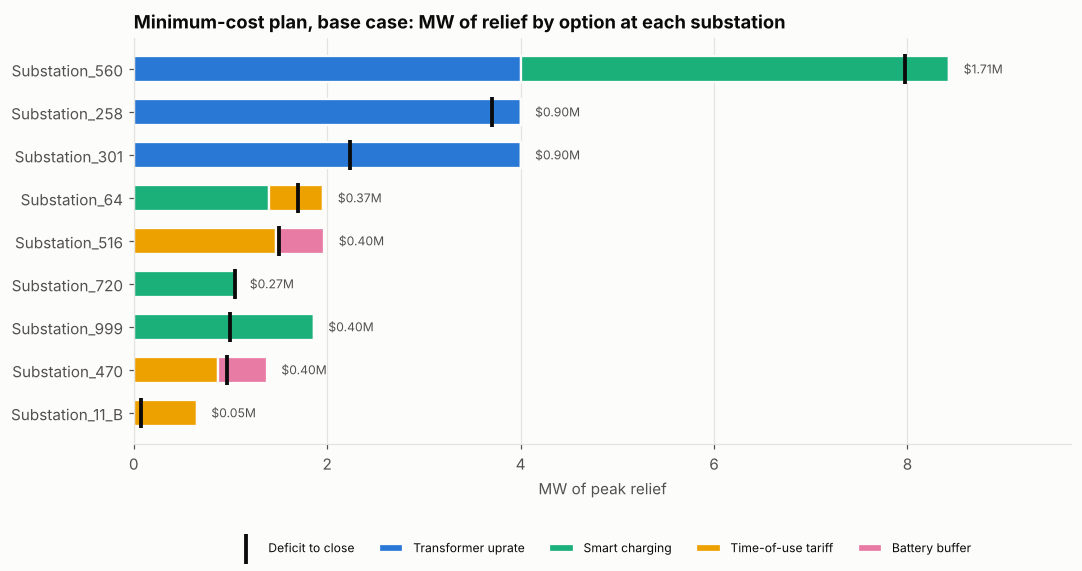

In [7]:
base_plan = plans["Base case (65% base load)"].sort_values("deficit_mw")
fig, ax = plt.subplots(figsize=(11, 4.8))
left = np.zeros(len(base_plan))
for color, opt in zip(SERIES, OPTIONS):
    vals = base_plan[f"relief_{opt}"].values
    if vals.sum() == 0:
        continue   # option not selected anywhere, so keep it out of the legend
    ax.barh(base_plan.index, vals, left=left, color=color, height=0.6, edgecolor=SURFACE, linewidth=1.5, label=opt)
    left += vals
ax.scatter(base_plan["deficit_mw"], base_plan.index, marker="|", s=400, color=INK, linewidth=2.5, zorder=4, label="Deficit to close")
for yi, (tot, c) in enumerate(zip(left, base_plan["cost_musd"])):
    ax.text(tot + 0.15, yi, f"${c:.2f}M", va="center", fontsize=8, color=INK_2)
ax.set(title="Minimum-cost plan, base case: MW of relief by option at each substation",
       xlabel="MW of peak relief", xlim=(0, left.max() * 1.15))
ax.legend(loc="lower center", bbox_to_anchor=(0.5, -0.3), ncol=6, fontsize=8)
ax.grid(axis="y", visible=False)
save(fig, "06_02_optimal_plan"); plt.show()

In [8]:
def describe(plan):
    return pd.DataFrame({
        "uprates": plan["uprates"].astype(int), "new bay": plan["new_bay"].astype(int),
        "smart charging": plan["smart_charging"].map({1: "yes", 0: ""}),
        "ToU tariff": plan["tou_tariff"].map({1: "yes", 0: ""}),
        "battery (MW)": plan["battery_blocks"] * RELIEF["battery_block"],
        "deficit (MW)": plan["deficit_mw"], "relief (MW)": plan["relief_mw"], "cost ($M)": plan["cost_musd"],
    }).sort_values("deficit (MW)", ascending=False)
describe(plans["Base case (65% base load)"])

,uprates,new bay,smart charging,ToU tariff,battery (MW),deficit (MW),relief (MW),cost ($M)
substation_id,,,,,,,,
Substation_560,1,0,yes,,0.00,7.97,8.43,1.71
Substation_258,1,0,,,0.00,3.70,4.00,0.90
Substation_301,1,0,,,0.00,2.24,4.00,0.90
Substation_64,0,0,yes,yes,0.00,1.70,1.96,0.37
Substation_516,0,0,,yes,0.50,1.50,1.97,0.40
Substation_720,0,0,yes,,0.00,1.05,1.05,0.27
Substation_999,0,0,yes,,0.00,1.00,1.86,0.40
Substation_470,0,0,,yes,0.50,0.96,1.38,0.40
Substation_11_B,0,0,,yes,0.00,0.07,0.65,0.05


**Reading it**
- Only 3 of the 9 substations need copper: one transformer uprate each at 258, 301, and 560. Substation_560 also needs smart charging on top, because its 8 MW deficit is larger than one uprate provides.
- The other 6 are solved without new equipment by smart charging, time-of-use tariffs, and small battery buffers. These costs are $0.05–0.40M each, compared with $0.9M for an uprate.
- A new transformer bay is never chosen. The deficits are all small enough that cheaper steps cover them.

## 5. Robust plan and 'no-regret' actions
If base load turns out to be 70%, the plan grows. Actions that appear in both plans are no-regret: they are needed whatever the true base load is, so they can be approved now with confidence.

In [9]:
robust_plan = plans["Robust case (70% base load)"]
describe(robust_plan)

,uprates,new bay,smart charging,ToU tariff,battery (MW),deficit (MW),relief (MW),cost ($M)
substation_id,,,,,,,,
Substation_560,2,0,yes,,0.00,11.22,12.43,2.61
Substation_516,1,0,,yes,0.50,5.90,5.97,1.30
Substation_258,1,0,yes,,0.00,4.80,5.75,1.28
Substation_470,0,0,yes,yes,0.50,3.56,3.57,0.85
Substation_301,1,0,,,0.00,3.24,4.00,0.90
Substation_999,1,0,,,0.00,3.15,4.00,0.90
Substation_64,1,0,,,0.00,3.00,4.00,0.90
Substation_816,0,0,yes,yes,0.00,2.60,3.19,0.51
Substation_11_B,0,0,yes,yes,0.00,2.22,2.28,0.41


In [10]:
cols = ["uprates", "new_bay", "smart_charging", "tou_tariff", "battery_blocks"]
base_p = plans["Base case (65% base load)"][cols]
rob_p = robust_plan[cols].reindex(base_p.index)
no_regret = base_p.where(base_p.le(rob_p), rob_p).clip(lower=0)   # the action level common to both plans
no_regret = no_regret[no_regret.sum(axis=1) > 0]
no_regret = no_regret.round().astype(int)
# Cost of the no-regret package (same unit costs as the optimiser)
ev20 = CASES["Base case (65% base load)"]["ev_peak_20x"].reindex(no_regret.index)
no_regret["cost_musd"] = (no_regret["uprates"] * COST["uprate"] + no_regret["new_bay"] * COST["bay"]
                          + no_regret["smart_charging"] * (COST["smart_fixed"] + COST["smart_per_mw"] * ev20)
                          + no_regret["tou_tariff"] * COST["tou"] + no_regret["battery_blocks"] * COST["battery_block"])
no_regret.to_csv(REPORTS / "no_regret_actions.csv")
print(f"No-regret actions at {len(no_regret)} substations, total ${no_regret['cost_musd'].sum():.2f}M:")
no_regret

No-regret actions at 6 substations, total $4.36M:


,uprates,new_bay,smart_charging,tou_tariff,battery_blocks,cost_musd
substation_id,,,,,,
Substation_560,1,0,1,0,0,1.71
Substation_258,1,0,0,0,0,0.90
Substation_301,1,0,0,0,0,0.90
Substation_516,0,0,0,1,1,0.40
Substation_470,0,0,0,1,1,0.40
Substation_11_B,0,0,0,1,0,0.05


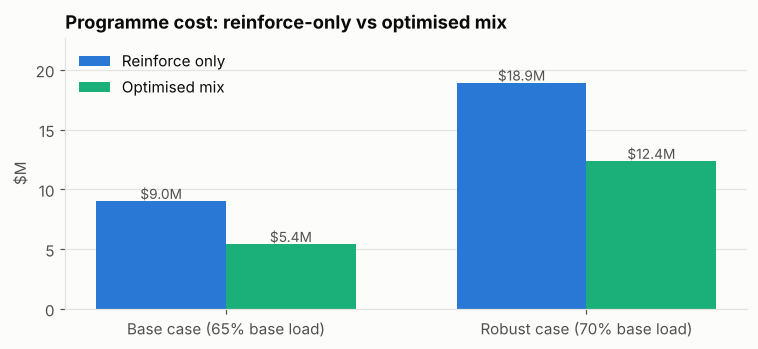

In [11]:
fig, ax = plt.subplots(figsize=(8, 3.2))
x = np.arange(len(comparison))
w = 0.36
ax.bar(x - w / 2, comparison["reinforce-only cost ($M)"], width=w, color=SERIES[0], label="Reinforce only")
ax.bar(x + w / 2, comparison["optimised cost ($M)"], width=w, color=SERIES[2], label="Optimised mix")
for xi, (a, b) in enumerate(zip(comparison["reinforce-only cost ($M)"], comparison["optimised cost ($M)"])):
    ax.text(xi - w / 2, a + 0.2, f"${a:.1f}M", ha="center", fontsize=9, color=INK_2)
    ax.text(xi + w / 2, b + 0.2, f"${b:.1f}M", ha="center", fontsize=9, color=INK_2)
ax.set_xticks(x, comparison.index)
ax.set(title="Programme cost: reinforce-only vs optimised mix", ylabel="$M", ylim=(0, comparison["reinforce-only cost ($M)"].max() * 1.2))
ax.legend(loc="upper left")
ax.grid(axis="x", visible=False)
save(fig, "06_03_cost_comparison"); plt.show()

## 6. Sensitivity: what if non-wire options under-deliver?
Smart charging and tariffs depend on customer behaviour. We re-solve with non-wire relief derated to 75% and to 50% of plan.

In [12]:
derate_rows = []
for name, d in CASES.items():
    for derate in (1.0, 0.75, 0.5):
        p = solve(d, derate=derate)
        derate_rows.append({"case": name, "non-wire delivery": derate, "cost ($M)": p["cost_musd"].sum(),
                            "uprates": int(p["uprates"].sum()), "new bays": int(p["new_bay"].sum()),
                            "smart programmes": int(p["smart_charging"].sum()), "ToU tariffs": int(p["tou_tariff"].sum()),
                            "battery MW": p["battery_blocks"].sum() * RELIEF["battery_block"]})
pd.DataFrame(derate_rows).style.format({"non-wire delivery": "{:.0%}", "cost ($M)": "${:.2f}M", "battery MW": "{:.1f}"})

,case,non-wire delivery,cost ($M),uprates,new bays,smart programmes,ToU tariffs,battery MW
0,Base case (65% base load),100%,$5.40M,3,0,4,4,1.0
1,Base case (65% base load),75%,$6.14M,3,0,5,5,1.0
2,Base case (65% base load),50%,$7.04M,6,0,3,2,0.0
3,Robust case (70% base load),100%,$12.35M,8,0,8,9,2.0
4,Robust case (70% base load),75%,$13.82M,10,0,9,6,0.5
5,Robust case (70% base load),50%,$15.79M,14,0,6,5,0.5


## 7. Model B: what to fund first under a budget cap
We sweep the budget from zero up to the robust plan's full cost. At each level, the optimiser fixes the set of substations with the highest total risk score that the money allows. This is the efficient frontier an investment committee needs.

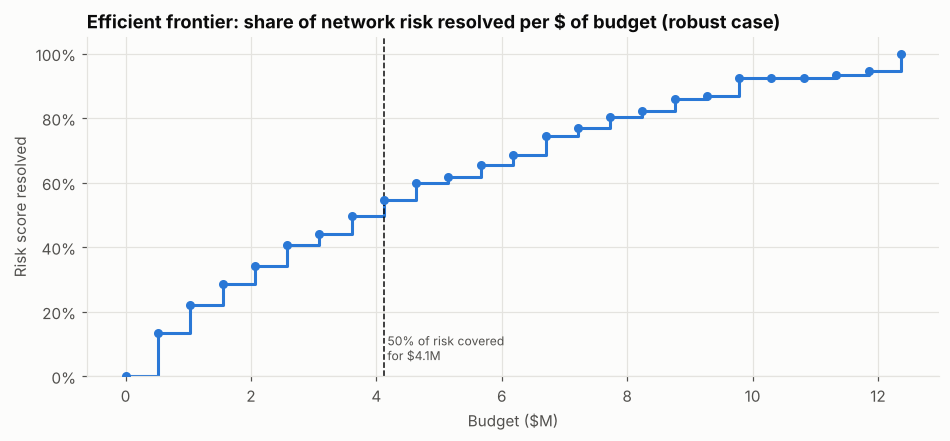

,budget_musd,spend_musd,substations_fixed,risk_covered_pct
0,0.00,0.00,0,0.00
3,1.55,1.49,6,0.29
6,3.09,2.71,9,0.44
9,4.64,4.51,11,0.60
12,6.18,5.79,12,0.69
15,7.73,7.59,14,0.80
18,9.27,8.89,15,0.87
21,10.82,9.74,16,0.92
24,12.36,12.35,17,1.00


In [13]:
d_rob = CASES["Robust case (70% base load)"]
full_cost = robust_plan["cost_musd"].sum()
budgets = np.round(np.linspace(0, full_cost + 0.01, 25), 2)
frontier = []
for B in budgets:
    p = solve(d_rob, budget=B)
    fixed = p.index[p["fixed"] == 1]
    frontier.append({"budget_musd": B, "spend_musd": p.loc[fixed, "cost_musd"].sum(), "substations_fixed": len(fixed),
                     "risk_covered_pct": d_rob.loc[fixed, "risk_score"].sum() / d_rob["risk_score"].sum(),
                     "fixed_list": ", ".join(s.replace("Substation_", "S") for s in fixed)})
frontier = pd.DataFrame(frontier)
frontier.to_csv(REPORTS / "budget_frontier.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4))
ax.step(frontier["budget_musd"], frontier["risk_covered_pct"], where="post", color=SERIES[0], linewidth=2)
ax.scatter(frontier["budget_musd"], frontier["risk_covered_pct"], color=SERIES[0], s=24, zorder=3)
half = frontier.loc[frontier["risk_covered_pct"] >= 0.5, "budget_musd"].min()
ax.axvline(half, color=INK, linestyle="--", linewidth=1)
ax.text(half, 0.05, f" 50% of risk covered\n for ${half:.1f}M", fontsize=8, color=INK_2)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set(title="Efficient frontier: share of network risk resolved per $ of budget (robust case)",
       xlabel="Budget ($M)", ylabel="Risk score resolved", ylim=(0, 1.05))
save(fig, "06_04_budget_frontier"); plt.show()
frontier[["budget_musd", "spend_musd", "substations_fixed", "risk_covered_pct"]].iloc[::3]

**Reading it**
- The first $0.5M resolves 13% of network risk at 3 substations, using tariffs and smart charging where deficits are small.
- $4.1M resolves half of the risk (10 of 17 substations). The full robust programme costs $12.4M.
- The curve flattens at the top. Going from ~92% to 100% costs about $2.6M more, because the last substations need extra transformer uprates.

This is the chart for the budget conversation: *"for $X we resolve Y% of the risk."*

## 8. Implementation roadmap: trigger-based phasing
Instead of fixed dates, which are impossible to set with 38 days of data, each action gets a trigger: start delivery when measured EV peak load at that substation reaches a set multiple of today's level. The trigger is set at 75% of the breaking multiple, to leave lead time for procurement and construction.

In [14]:
cap_info = capacity_model(events, subs, CHARGER_KW, 0.65, COINCIDENCE, PLANNING_LIMIT)
roadmap = describe(robust_plan).join(cap_info[["breaking_multiple"]]).join(scores[["tier"]])
roadmap["trigger_multiple"] = (roadmap["breaking_multiple"] * 0.75).round(1)
roadmap["no_regret"] = roadmap.index.isin(no_regret.index)
roadmap["phase"] = np.select([roadmap["trigger_multiple"] <= 10, roadmap["trigger_multiple"] <= 15],
                             ["Phase 1 (trigger <= 10x)", "Phase 2 (10-15x)"], "Phase 3 (> 15x)")
roadmap = roadmap.sort_values("trigger_multiple")
roadmap.to_csv(REPORTS / "upgrade_plan.csv")
roadmap.groupby("phase").agg(substations=("cost ($M)", "size"), cost_musd=("cost ($M)", "sum"),
                             no_regret=("no_regret", "sum"))

,substations,cost_musd,no_regret
phase,,,
Phase 1 (trigger <= 10x),3,4.79,3
Phase 2 (10-15x),6,5.26,3
Phase 3 (> 15x),8,2.30,0


In [15]:
roadmap

,uprates,new bay,smart charging,ToU tariff,battery (MW),deficit (MW),relief (MW),cost ($M),breaking_multiple,tier,trigger_multiple,no_regret,phase
substation_id,,,,,,,,,,,,,
Substation_258,1,0,yes,,0.00,4.80,5.75,1.28,9.43,Tier 1 - Act,7.10,True,Phase 1 (trigger <= 10x)
Substation_560,2,0,yes,,0.00,11.22,12.43,2.61,11.00,Tier 1 - Act,8.30,True,Phase 1 (trigger <= 10x)
Substation_301,1,0,,,0.00,3.24,4.00,0.90,11.46,Tier 1 - Act,8.60,True,Phase 1 (trigger <= 10x)
Substation_64,1,0,,,0.00,3.00,4.00,0.90,13.93,Tier 1 - Act,10.40,False,Phase 2 (10-15x)
Substation_720,1,0,,,0.00,2.10,4.00,0.90,15.00,Tier 1 - Act,11.30,False,Phase 2 (10-15x)
Substation_999,1,0,,,0.00,3.15,4.00,0.90,17.32,Tier 1 - Act,13.00,False,Phase 2 (10-15x)
Substation_470,0,0,yes,yes,0.50,3.56,3.57,0.85,17.80,Tier 1 - Act,13.40,True,Phase 2 (10-15x)
Substation_516,1,0,,yes,0.50,5.90,5.97,1.30,17.96,Tier 1 - Act,13.50,True,Phase 2 (10-15x)
Substation_11_B,0,0,yes,yes,0.00,2.22,2.28,0.41,19.77,Tier 1 - Act,14.80,True,Phase 2 (10-15x)


## 9. Summary

| Question | Answer |
|---|---|
| What is the cheapest compliant plan? | Base case: $5.4M across 9 substations. It uses 3 transformer uprates (258, 301, 560), with smart charging, time-of-use tariffs, and small batteries everywhere else. A new transformer bay is never needed. |
| How much does optimisation save? | 40% versus reinforce-only in the base case ($5.4M vs $9.0M), and 35% in the robust case ($12.4M vs $18.9M) |
| Does it survive if non-wire options under-deliver? | Yes. At 50% delivery, the optimised plan still costs less than reinforce-only ($7.0M vs $9.0M base, $15.8M vs $18.9M robust). |
| What can be approved today? | No-regret actions at 6 substations, needed under both base-load assumptions: uprates at 258, 301, and 560, smart charging at 560, and tariffs plus small batteries at 516, 470, and 11_B |
| What if the budget is capped? | $4.1M resolves 50% of network risk (efficient frontier, section 7) |
| When should each action start? | Phase 1 (3 substations, $4.8M) when EV peak reaches ≤ 10× today. Later phases follow their own triggers, so spending is tied to observed growth, not forecasts. |

**Next:** `07_geospatial_analysis.ipynb`: map the substations, charging stations, bottleneck tiers, and the upgrade plan with GeoPandas.